# Quantum Optimisation of Retroactive Rebate Programs

## Purpose

Retroactive (all-units) rebate tiers are among the most common incentive structures in B2B commercial strategy, and among the hardest to design well. When a customer's volume crosses a threshold, the higher rebate rate applies to **every unit purchased in the period**, not just the units above it. That creates discontinuities ("cliffs") in both the customer's net price and the supplier's margin. It also turns the design of a program's thresholds and rates into a combinatorial optimisation problem that scales poorly as tiers, customers and constraints grow.

This notebook asks one research question:

> **Can rebate program design be formulated as a quantum optimisation problem, and does a hybrid quantum-classical approach built on NVIDIA CUDA-Q offer a useful new way to construct retroactive tier structures?**

## Why retroactive tiers matter

A retroactive tier schedule with thresholds $0 = t_0 < t_1 < \dots < t_K$ and rates $r_0 < r_1 < \dots < r_K$ pays a rebate of

$$
R(q) = r_k \, q \quad \text{for } t_k \le q < t_{k+1}
$$

on period volume $q$. Unlike an incremental schedule, $R(q)$ is discontinuous. At each threshold the payout jumps by

$$
\Delta R_k = (r_k - r_{k-1})\, t_k ,
$$

so the effective marginal price just below a threshold can become negative. This gives suppliers behavioural leverage over customers near a threshold. It also creates a risk of margin leakage when thresholds are badly placed, and a discrete, non-convex design problem across a portfolio of customers.

## Structure of the notebook

**Part 1: Deriving retroactive rebate tiers.** This part covers flat, incremental and retroactive schedules, the rebate function and its cliffs, customer volume as a random variable, expected rebate liability and supplier margin, and why the design space grows combinatorially.

**Part 2: Basics of quantum computing.** This part covers qubits, gates and circuits, entanglement and interference, Hamiltonians as cost functions, QUBO and Ising formulations, the Quantum Approximate Optimisation Algorithm (QAOA), and an introduction to the CUDA-Q programming model.

**Part 3: A new quantum approach to constructing rebate programs.** This part encodes candidate thresholds and rates as binary variables and builds a cost Hamiltonian from the Part 1 margin objective. Penalty terms enforce tier ordering, budget and encoding validity. The part then implements and optimises a QAOA circuit in CUDA-Q on GPU-accelerated simulation, decodes the results into tier schedules, and benchmarks them against classical methods.

## Scope

This is exploratory research. All quantum results come from simulation, and no quantum advantage is claimed. The aim is to show that rebate design maps naturally onto quantum optimisation, and to compare it honestly against classical baselines.

# Part 1: Basics of Retroactive Volume Rebates

A **volume rebate** is a payment from a supplier back to a customer once the customer's purchase volume over an agreed period (here, one year) reaches set thresholds. In a **retroactive** (all-units) rebate, reaching a higher tier moves *all* volume in the period to the higher rate, including volume bought before the threshold was crossed.

## 1.1 Constructing a 3-tier program

Consider a single product sold at a list price of **£50 per unit**. The supplier offers this annual program, with the rebate calculated as a percentage of spend:

| Tier | Annual volume (units) | Rebate rate |
|---|---|---|
| 1 | 0 – 9,999 | 0% |
| 2 | 10,000 – 24,999 | 2% |
| 3 | 25,000 + | 4% |

Formally, with thresholds $t_1 = 0$, $t_2 = 10{,}000$, $t_3 = 25{,}000$ and rates $r_1 = 0$, $r_2 = 0.02$, $r_3 = 0.04$, the rate that applies to cumulative volume $Q$ is

$$
r(Q) = r_k \quad \text{for } t_k \le Q < t_{k+1},
$$

and the rebate owed on cumulative spend $S = p\,Q$ is

$$
R(Q) = r(Q)\, S .
$$

## 1.2 Calculating the rebate across the year

Rebates are usually settled periodically (here, quarterly) against **cumulative year-to-date (YTD)** volume. Because the rate is retroactive, each time the customer moves up a tier, earlier purchases must be re-rated at the new rate. This catch-up payment is the **true-up**.

In each quarter $n$:

$$
E_n = r(Q_n)\, S_n \qquad\text{(cumulative entitlement to date)}
$$

$$
P_n = E_n - E_{n-1} \qquad\text{(payment due this quarter, including any true-up)}
$$

Suppose the customer buys the following volumes:

| Quarter | Units | Spend | YTD units | YTD spend | Tier reached | YTD entitlement $E_n$ | Payment $P_n$ |
|---|---|---|---|---|---|---|---|
| Q1 | 6,000 | £300,000 | 6,000 | £300,000 | 1 (0%) | £0 | £0 |
| Q2 | 7,000 | £350,000 | 13,000 | £650,000 | 2 (2%) | £13,000 | £13,000 |
| Q3 | 8,000 | £400,000 | 21,000 | £1,050,000 | 2 (2%) | £21,000 | £8,000 |
| Q4 | 9,000 | £450,000 | 30,000 | £1,500,000 | 3 (4%) | £60,000 | £39,000 |
| **Total** | **30,000** | **£1,500,000** | | | | | **£60,000** |

**The true-ups:**

- **Q2.** The customer crosses 10,000 units. The Q2 payment of £13,000 is 2% of Q2 spend (£7,000) plus a **£6,000 true-up** that re-rates Q1's £300,000 from 0% to 2%.
- **Q3.** The customer stays in Tier 2, so there is no true-up. The payment is 2% of Q3 spend: £8,000.
- **Q4.** The customer crosses 25,000 units. The Q4 payment of £39,000 is 4% of Q4 spend (£18,000) plus a **£21,000 true-up** that re-rates the £1,050,000 bought in Q1–Q3 from 2% to 4%.

**Annual outcome for the supplier:**

$$
\text{Net revenue} = S - R = £1{,}500{,}000 - £60{,}000 = £1{,}440{,}000
$$

This gives an effective net price of $£1{,}440{,}000 / 30{,}000 = £48.00$ per unit, an overall discount of 4%.

## 1.3 The tier cliff

The retroactive structure creates a discontinuity at every threshold. Just below and just above Tier 3:

| Annual units | Spend | Rate | Rebate | Net revenue |
|---|---|---|---|---|
| 24,999 | £1,249,950 | 2% | £24,999 | £1,224,951 |
| 25,000 | £1,250,000 | 4% | £50,000 | £1,200,000 |

Selling **one more unit** raises the rebate by about **£25,000** and *reduces* the supplier's net revenue by £24,951. In general, the size of the cliff at threshold $t_k$ is

$$
\Delta R_k = (r_k - r_{k-1})\, p\, t_k = (0.04 - 0.02) \times £50 \times 25{,}000 = £25{,}000 .
$$

The cliff has two sides:

- **For the customer**, it is a strong incentive to push volume over the threshold. This is the behavioural lever the program is designed to create.
- **For the supplier**, it is a source of margin risk. A threshold placed where customers would have landed anyway pays the higher rate on the whole year's volume for no change in behaviour.

Choosing where to place thresholds and how to set rates, across many customers with uncertain volumes, is the optimisation problem the rest of this notebook develops.

In [21]:
# --- 1.1 The rebate program ---------------------------------------------

price = 50  # £ per unit

# Each tier: (minimum annual units, rebate rate)
tiers = [
    (0,      0.00),  # Tier 1
    (10_000, 0.02),  # Tier 2
    (25_000, 0.04),  # Tier 3
]


def rebate_rate(units):
    """Return the rate for the highest tier the volume has reached."""
    rate = 0.0
    for threshold, tier_rate in tiers:
        if units >= threshold:
            rate = tier_rate
    return rate


def rebate(units):
    """Retroactive rebate: the tier rate applies to ALL spend."""
    return rebate_rate(units) * units * price


# --- 1.2 Calculating the rebate across the year ---------------------------

quarterly_units = {"Q1": 6_000, "Q2": 7_000, "Q3": 8_000, "Q4": 9_000}

ytd_units = 0
paid_so_far = 0

print(f"{'Qtr':<4}{'Units':>8}{'YTD units':>11}{'Rate':>7}{'Entitlement':>13}{'Payment':>10}{'True-up':>10}")

for quarter, units in quarterly_units.items():
    rate_before = rebate_rate(ytd_units)       # rate before this quarter's purchases
    ytd_units += units

    entitlement = rebate(ytd_units)            # E_n: total owed on YTD spend
    payment = entitlement - paid_so_far        # P_n = E_n - E_(n-1)
    true_up = (rebate_rate(ytd_units) - rate_before) * (ytd_units - units) * price  # re-rating earlier spend
    paid_so_far = entitlement

    print(f"{quarter:<4}{units:>8,}{ytd_units:>11,}{rebate_rate(ytd_units):>7.0%}"
          f"{entitlement:>13,.0f}{payment:>10,.0f}{true_up:>10,.0f}")

total_spend = ytd_units * price
total_rebate = rebate(ytd_units)
net_revenue = total_spend - total_rebate

print()
print(f"Total spend:       £{total_spend:,.0f}")
print(f"Total rebate:      £{total_rebate:,.0f}")
print(f"Net revenue:       £{net_revenue:,.0f}")
print(f"Net price per unit: £{net_revenue / ytd_units:.2f}")


# --- 1.3 The tier cliff ---------------------------------------------------

print()
for units in [24_999, 25_000]:
    spend = units * price
    print(f"{units:,} units -> rebate £{rebate(units):,.0f}, net revenue £{spend - rebate(units):,.0f}")

print(f"Cliff at 25,000 units: £{rebate(25_000) - rebate(24_999):,.0f}")

Qtr    Units  YTD units   Rate  Entitlement   Payment   True-up
Q1     6,000      6,000     0%            0         0         0
Q2     7,000     13,000     2%       13,000    13,000     6,000
Q3     8,000     21,000     2%       21,000     8,000         0
Q4     9,000     30,000     4%       60,000    39,000    21,000

Total spend:       £1,500,000
Total rebate:      £60,000
Net revenue:       £1,440,000
Net price per unit: £48.00

24,999 units -> rebate £24,999, net revenue £1,224,951
25,000 units -> rebate £50,000, net revenue £1,200,000
Cliff at 25,000 units: £25,001


# Part 2: A Basic Introduction to Qubits

## 2.1 A single qubit

A classical **bit** is always either `0` or `1`. A **qubit** can also be `0` or `1`, which we write as the states $|0\rangle$ and $|1\rangle$. It can also be in a **superposition**, a blend of the two:

$$
|\psi\rangle = \alpha\,|0\rangle + \beta\,|1\rangle
$$

The numbers $\alpha$ and $\beta$ are called **amplitudes**. They set the probability of each result when the qubit is measured:

$$
P(0) = |\alpha|^2, \qquad P(1) = |\beta|^2, \qquad |\alpha|^2 + |\beta|^2 = 1
$$

**Measurement** always gives a plain `0` or `1`, never a blend. Once measured, the qubit stays in the state that was observed, and the superposition is gone.

*Example:* with $\alpha = \beta = \tfrac{1}{\sqrt{2}}$, the qubit is an equal blend. Measuring it gives `0` half the time and `1` half the time, like a fair coin toss.

## 2.2 The Bloch sphere

A single qubit can be pictured as an **arrow pointing from the centre of a sphere to its surface**. This is the Bloch sphere.

- The **north pole** is $|0\rangle$.
- The **south pole** is $|1\rangle$.
- Every other point on the surface is a superposition.

The direction of the arrow is given by two angles: $\theta$, measured down from the north pole, and $\phi$, measured around the equator. In terms of these angles, the state is

$$
|\psi\rangle = \cos\!\left(\tfrac{\theta}{2}\right)|0\rangle + e^{i\phi}\sin\!\left(\tfrac{\theta}{2}\right)|1\rangle
$$

**Measuring on the Bloch sphere.** A measurement asks one question: *is the arrow up or down?* The closer the arrow is to a pole, the more likely that result:

$$
P(0) = \cos^2\!\left(\tfrac{\theta}{2}\right), \qquad P(1) = \sin^2\!\left(\tfrac{\theta}{2}\right)
$$

| Arrow position | $\theta$ | $P(0)$ | $P(1)$ |
|---|---|---|---|
| North pole | 0° | 100% | 0% |
| Upper half | 60° | 75% | 25% |
| Equator | 90° | 50% | 50% |
| South pole | 180° | 0% | 100% |

After a measurement, the arrow **snaps to the pole** matching the result. The angle $\phi$ has no effect on these probabilities. It becomes important once qubits interact, but it can be set aside for now.

## 2.3 Two qubits

With two qubits there are **four** basic states, one for each pair of classical values:

$$
|00\rangle, \quad |01\rangle, \quad |10\rangle, \quad |11\rangle
$$

A two-qubit state can be a superposition of all four, with one amplitude each:

$$
|\psi\rangle = a\,|00\rangle + b\,|01\rangle + c\,|10\rangle + d\,|11\rangle, \qquad |a|^2 + |b|^2 + |c|^2 + |d|^2 = 1
$$

Measuring both qubits gives one of the four pairs, with probability $|a|^2$, $|b|^2$, $|c|^2$ or $|d|^2$.

The number of states grows quickly. Every extra qubit **doubles** the number of basic states, so $n$ qubits hold amplitudes for $2^n$ combinations at once. With 10 qubits that is 1,024 combinations, and with 50 qubits it is about $10^{15}$. This is what makes qubits interesting for search problems like choosing rebate tiers.

## 2.4 The CNOT operation

The **CNOT** (controlled-NOT) acts on two qubits: a **control** and a **target**.

> *If the control is `1`, flip the target. Otherwise, do nothing.*

| Before (control, target) | After |
|---|---|
| $\lvert 00\rangle$ | $\lvert 00\rangle$ |
| $\lvert 01\rangle$ | $\lvert 01\rangle$ |
| $\lvert 10\rangle$ | $\lvert 11\rangle$ |
| $\lvert 11\rangle$ | $\lvert 10\rangle$ |

With plain `0`s and `1`s, this behaves just like a classical "if" statement. Something new happens when the control is in a **superposition**.

## 2.5 Entanglement

Start with the control in an equal blend and the target at $|0\rangle$:

$$
\tfrac{1}{\sqrt{2}}\big(|0\rangle + |1\rangle\big) \otimes |0\rangle = \tfrac{1}{\sqrt{2}}\big(|00\rangle + |10\rangle\big)
$$

Apply CNOT. The $|00\rangle$ part is unchanged, and the $|10\rangle$ part becomes $|11\rangle$:

$$
\tfrac{1}{\sqrt{2}}\big(|00\rangle + |11\rangle\big)
$$

This is an **entangled** state, called a *Bell state*. Measuring it gives:

| Result | Probability |
|---|---|
| `00` | 50% |
| `11` | 50% |
| `01` or `10` | 0% |

Each qubit on its own is still a 50/50 coin toss, but **the two results always match**. Measuring one qubit immediately tells you the other.

**On the Bloch sphere,** the two qubits can no longer be drawn as two separate arrows, because neither qubit has a state of its own; the information is held in the *relationship* between them. If you look at just one qubit, its arrow shrinks to the **centre** of the sphere. That represents a completely random result that depends entirely on its partner.

## Summary

| Idea | In plain terms |
|---|---|
| Qubit | A bit that can be a blend of `0` and `1` |
| Amplitudes | Numbers that set the odds of each result |
| Measurement | Always gives `0` or `1`, and fixes the qubit in that state |
| Bloch sphere | An arrow for one qubit: up is `0`, down is `1`, and height sets the odds |
| Two qubits | Four combinations; $n$ qubits give $2^n$ |
| CNOT | Flip the target if the control is `1` |
| Entanglement | Linked qubits whose results are correlated and can't be described separately |

Single qubit: tilt the arrow, then measure
 theta   alpha    beta  P(0) theory  P(0) measured
    0°   1.000   0.000         100%           100%
   60°   0.866   0.500          75%            74%
   90°   0.707   0.707          50%            48%
  180°   0.000   1.000           0%             0%


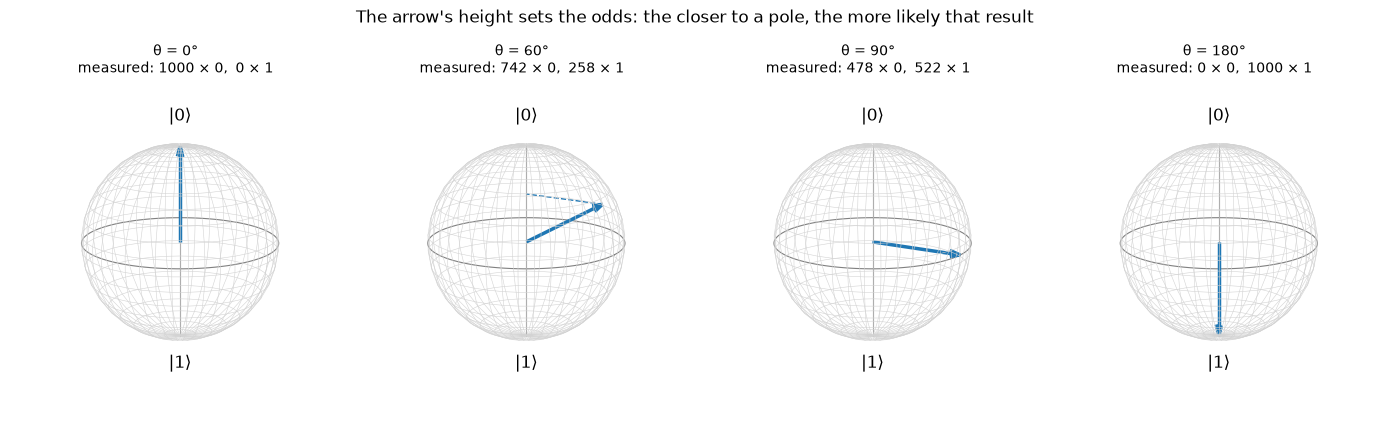


CNOT truth table (control, target)
  |00>  ->  |00>
  |01>  ->  |01>
  |10>  ->  |11>
  |11>  ->  |10>


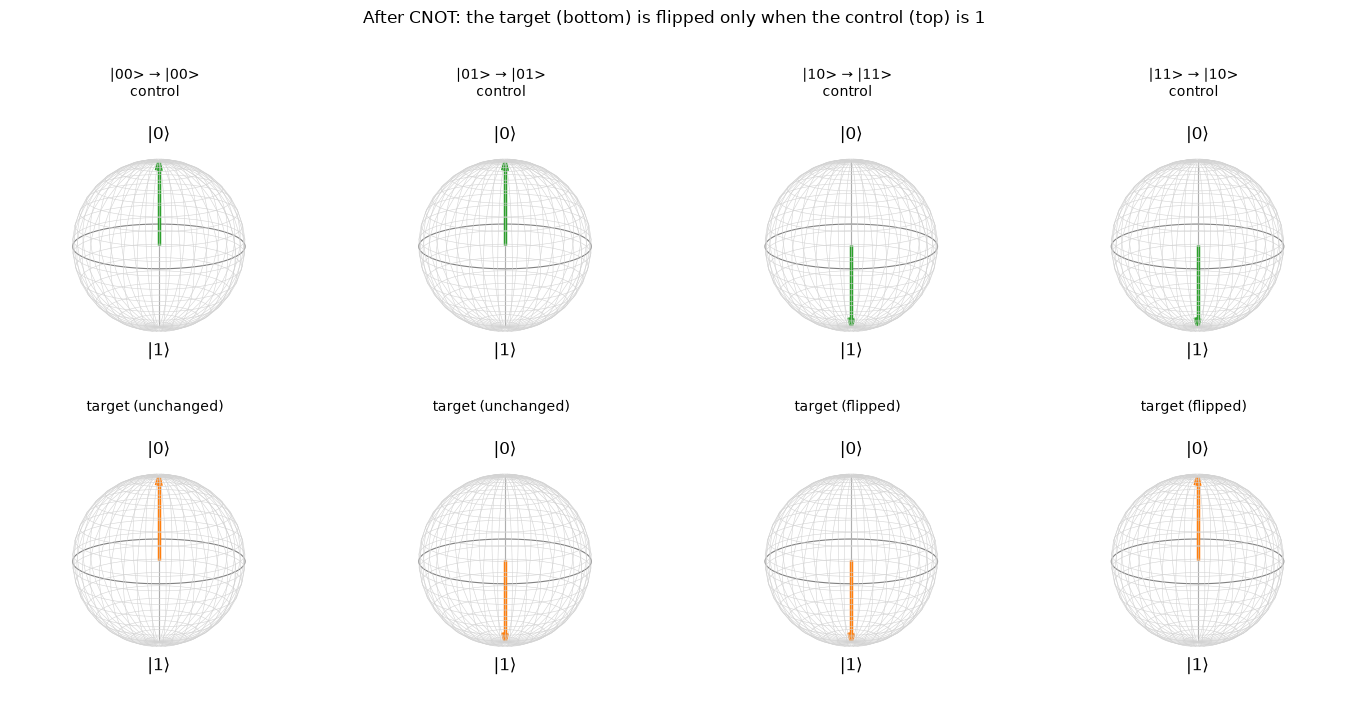


Entangled (Bell) state amplitudes
  |00>: 0.707   (probability 50%)
  |01>: 0.000   (probability 0%)
  |10>: 0.000   (probability 0%)
  |11>: 0.707   (probability 50%)

Measured 1000 times:
  00: 519
  01: 0
  10: 0
  11: 481
The two qubits always agree: only 00 and 11 appear.


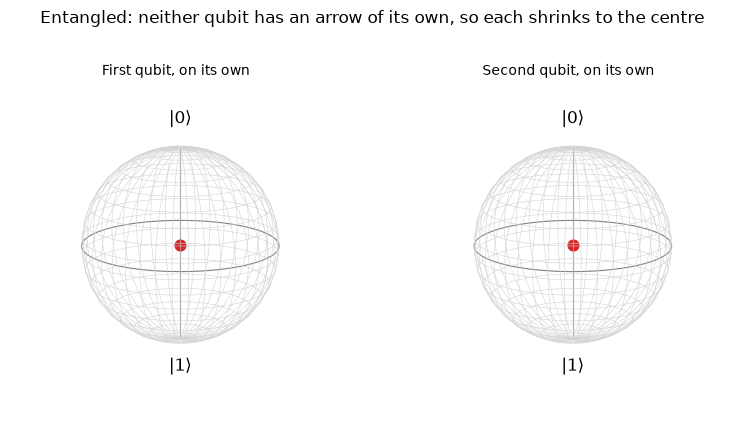

In [22]:
#Introduction to cubits, bloch sphere, CNOT and entanglement 
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # hide CUDA-Q API-change notice

import cudaq
import numpy as np
import matplotlib.pyplot as plt

SHOTS = 1000  # how many times to prepare and measure each state


# --- Helpers for drawing the Bloch sphere ------------------------------------

def qubit_on_its_own(state, which):
    """2x2 density matrix for one qubit of a 1- or 2-qubit state."""
    state = np.array(state)
    if len(state) == 2:
        return np.outer(state, state.conj())
    grid = state.reshape(2, 2).T            # CUDA-Q stores qubit 0 as the last binary digit
    if which == 1:                          # rows = the qubit we want to look at
        grid = grid.T
    return grid @ grid.conj().T


def bloch_vector(rho):
    """Arrow (x, y, z) for a single qubit. Height z = P(0) - P(1)."""
    return 2 * rho[1, 0].real, 2 * rho[1, 0].imag, (rho[0, 0] - rho[1, 1]).real


def draw_bloch(ax, rho, title, colour="tab:blue"):
    """Draw one Bloch sphere with the qubit's arrow."""
    u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
    ax.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v),
                      color="lightgrey", linewidth=0.4)
    t = np.linspace(0, 2 * np.pi, 100)
    ax.plot(np.cos(t), np.sin(t), 0, color="grey", linewidth=0.8)        # equator
    ax.plot([0, 0], [0, 0], [-1, 1], color="grey", linewidth=0.8)        # vertical axis
    ax.text(0, 0, 1.25, r"$|0\rangle$", ha="center", fontsize=12)
    ax.text(0, 0, -1.35, r"$|1\rangle$", ha="center", fontsize=12)

    x, y, z = bloch_vector(rho)
    if np.sqrt(x**2 + y**2 + z**2) < 0.01:
        ax.scatter([0], [0], [0], color=colour, s=60)                   # arrow shrunk to a point
    else:
        ax.quiver(0, 0, 0, x, y, z, color=colour, linewidth=2.5, arrow_length_ratio=0.12)
        ax.plot([x, 0], [y, 0], [z, z], color=colour, linestyle="--", linewidth=1)  # height

    ax.set_title(title, fontsize=10)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
    ax.set_box_aspect([1, 1, 1])
    ax.view_init(elev=15, azim=-60)
    ax.set_axis_off()


# --- 2.1 / 2.2 A single qubit on the Bloch sphere ---------------------------

@cudaq.kernel
def one_qubit(theta: float):
    q = cudaq.qubit()   # starts at the north pole, |0>
    ry(theta, q)        # tilt the arrow down from the north pole by angle theta


angles = [0, 60, 90, 180]

print("Single qubit: tilt the arrow, then measure")
print(f"{'theta':>6}{'alpha':>8}{'beta':>8}{'P(0) theory':>13}{'P(0) measured':>15}")

fig = plt.figure(figsize=(14, 4))
for i, degrees in enumerate(angles):
    theta = np.radians(degrees)

    state = cudaq.get_state(one_qubit, theta)                   # the two amplitudes
    alpha, beta = np.array(state)
    counts = cudaq.sample(one_qubit, theta, shots_count=SHOTS)  # measure SHOTS times

    print(f"{degrees:>5}°{alpha.real:>8.3f}{beta.real:>8.3f}"
          f"{abs(alpha)**2:>13.0%}{counts.count('0') / SHOTS:>15.0%}")

    ax = fig.add_subplot(1, len(angles), i + 1, projection="3d")
    draw_bloch(ax, qubit_on_its_own(state, 0),
               f"θ = {degrees}°\nmeasured: {counts.count('0')} × 0,  {counts.count('1')} × 1")

fig.suptitle("The arrow's height sets the odds: the closer to a pole, the more likely that result", y=1.05)
plt.tight_layout()
plt.show()


# --- 2.3 / 2.4 Two qubits and the CNOT --------------------------------------

@cudaq.kernel
def cnot_example(control: int, target: int):
    q = cudaq.qvector(2)   # two qubits, both starting at |0>
    if control == 1:
        x(q[0])            # set the control to 1
    if target == 1:
        x(q[1])            # set the target to 1
    x.ctrl(q[0], q[1])     # CNOT: flip the target if the control is 1


print("\nCNOT truth table (control, target)")

fig = plt.figure(figsize=(14, 7))
inputs = [(0, 0), (0, 1), (1, 0), (1, 1)]
for i, (control, target) in enumerate(inputs):
    result = cudaq.sample(cnot_example, control, target).most_probable()
    print(f"  |{control}{target}>  ->  |{result}>")

    state = cudaq.get_state(cnot_example, control, target)
    ax = fig.add_subplot(2, 4, i + 1, projection="3d")
    draw_bloch(ax, qubit_on_its_own(state, 0), f"|{control}{target}> → |{result}>\ncontrol", "tab:green")
    ax = fig.add_subplot(2, 4, i + 5, projection="3d")
    flipped = "flipped" if control == 1 else "unchanged"
    draw_bloch(ax, qubit_on_its_own(state, 1), f"target ({flipped})", "tab:orange")

fig.suptitle("After CNOT: the target (bottom) is flipped only when the control (top) is 1", y=1.02)
plt.tight_layout()
plt.show()


# --- 2.5 Entanglement --------------------------------------------------------

@cudaq.kernel
def bell():
    q = cudaq.qvector(2)
    h(q[0])                # put the control into an equal blend of 0 and 1
    x.ctrl(q[0], q[1])     # CNOT links the target to the control


state = cudaq.get_state(bell)
print("\nEntangled (Bell) state amplitudes")
for label, amp in zip(["00", "01", "10", "11"], np.array(state)):
    print(f"  |{label}>: {amp.real:.3f}   (probability {abs(amp)**2:.0%})")

counts = cudaq.sample(bell, shots_count=SHOTS)
print(f"\nMeasured {SHOTS} times:")
for outcome in ["00", "01", "10", "11"]:
    print(f"  {outcome}: {counts.count(outcome)}")
print("The two qubits always agree: only 00 and 11 appear.")

fig = plt.figure(figsize=(8, 4))
for i, name in enumerate(["First qubit", "Second qubit"]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    draw_bloch(ax, qubit_on_its_own(state, i), f"{name}, on its own", "tab:red")

fig.suptitle("Entangled: neither qubit has an arrow of its own, so each shrinks to the centre", y=1.05)
plt.tight_layout()
plt.show()


# Part 3: Introduction to Quantum Gates and Quantum Circuits

## 3.1 What is a gate?

A **quantum gate** is an operation that changes a qubit's state. On the Bloch sphere, every single-qubit gate is a **rotation**: it turns the arrow to a new position without changing its length.

Behind the picture, a gate is a small table of numbers (a matrix) that mixes the two amplitudes. For example, the X gate swaps them:

$$
X \begin{pmatrix} \alpha \\ \beta \end{pmatrix} = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}\begin{pmatrix} \alpha \\ \beta \end{pmatrix} = \begin{pmatrix} \beta \\ \alpha \end{pmatrix}
$$

## 3.2 The essential single-qubit gates

| Gate | What it does | On the Bloch sphere | Starting from $\lvert 0\rangle$ |
|---|---|---|---|
| **X** (NOT) | Swaps $\alpha$ and $\beta$ | Half-turn, flipping top and bottom | $\lvert 1\rangle$: always measures `1` |
| **H** (Hadamard) | Creates an equal blend | Moves a pole to the equator | $\tfrac{1}{\sqrt2}(\lvert 0\rangle + \lvert 1\rangle)$: 50/50 |
| **Z** (phase flip) | Flips the sign of $\beta$ | Half-turn around the vertical axis | No visible change: still measures `0` |
| **RY($\theta$)** | Tilts the arrow by any angle | Rotates down from the north pole by $\theta$ | $P(1) = \sin^2(\theta/2)$ |

The matrices behind them are:

$$
X = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}, \quad
H = \tfrac{1}{\sqrt2}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}, \quad
Z = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}, \quad
R_Y(\theta) = \begin{pmatrix} \cos\frac{\theta}{2} & -\sin\frac{\theta}{2} \\ \sin\frac{\theta}{2} & \cos\frac{\theta}{2} \end{pmatrix}
$$

**RY is the most important gate for this notebook.** A single number, the angle $\theta$, sets the odds of measuring `1` anywhere between 0% and 100%. This is how a probability (such as "the chance a customer reaches Tier 3") gets loaded into a qubit.

**Z shows that odds aren't the whole story.** Z changes the sign of $\beta$, which moves the arrow around the equator, but the measurement odds stay the same. That hidden sign, the **phase**, still matters, as 3.4 shows.

## 3.3 Gates can be undone

Every gate is a rotation, so every gate can be reversed by rotating back. X, H and Z are each their own reverse:

$$
X\,X = H\,H = Z\,Z = \text{do nothing}
$$

**Measurement is the only step that can't be undone.** It collapses the qubit to `0` or `1`, and the amplitudes are lost. For this reason, a calculation keeps its qubits unmeasured for as long as possible and measures only at the very end.

## 3.4 Interference: why phase matters

Compare two short sequences, both starting from $|0\rangle$:

| Sequence | Step by step | Result |
|---|---|---|
| H, then H | $\lvert 0\rangle \to \tfrac{1}{\sqrt2}(\lvert 0\rangle + \lvert 1\rangle) \to \lvert 0\rangle$ | Always `0` |
| H, then Z, then H | $\lvert 0\rangle \to \tfrac{1}{\sqrt2}(\lvert 0\rangle + \lvert 1\rangle) \to \tfrac{1}{\sqrt2}(\lvert 0\rangle - \lvert 1\rangle) \to \lvert 1\rangle$ | Always `1` |

In the middle, both sequences measure 50/50; the only difference is a minus sign. Yet the final results are opposite. Amplitudes can **add up** (constructive interference) or **cancel out** (destructive interference), just like waves.

This is the core idea behind quantum algorithms: arrange the gates so that the amplitudes of wrong answers cancel and the amplitudes of the right answer add up. A quantum computer can hold many possible answers in superposition at once, but measuring it returns only one of them, picked at random, so superposition alone gives no advantage. The skill in designing a quantum algorithm is choosing a sequence of gates that uses interference to raise the probability of the answer we want before measuring, so that it becomes the result most likely to appear.

## 3.5 Two-qubit gates

**CNOT** (from Part 2) flips the target when the control is `1`.

Any gate can be given a control in the same way. The **controlled-RY** rotates the target by $\theta$ *only* when the control is `1`. This lets one qubit's value decide how likely another qubit is to be `1`, which is exactly the kind of "if this, then that probability" logic needed to model customers moving between rebate tiers.

## 3.6 Quantum circuits

A **quantum circuit** is a recipe: a list of gates applied to qubits in order. It is drawn as a diagram:

- Each **horizontal line** is one qubit.
- **Time runs left to right.**
- Each **box** is a gate.
- A **dot joined to a box** is a controlled gate. The dot marks the control.

The Bell state from Part 2 is this circuit:

```
     ╭───╮
q0 : ┤ h ├──●──
     ╰───╯╭─┴─╮
q1 : ─────┤ x ├
          ╰───╯
```

Reading left to right:

| Step | Gate | State |
|---|---|---|
| Start | | $\lvert 00\rangle$ |
| 1 | H on q0 | $\tfrac{1}{\sqrt2}(\lvert 00\rangle + \lvert 10\rangle)$ |
| 2 | CNOT (q0 controls q1) | $\tfrac{1}{\sqrt2}(\lvert 00\rangle + \lvert 11\rangle)$ |
| End | Measure both | `00` or `11`, 50/50 |

In CUDA-Q, a circuit is written as a **kernel**: a Python function marked with `@cudaq.kernel`. Calling `cudaq.draw` on a kernel prints its circuit diagram.

## Summary

| Idea | In plain terms |
|---|---|
| Gate | A rotation of the qubit's arrow |
| X, H, Z | Flip, blend, and phase-flip |
| RY($\theta$) | Dial in any probability of measuring `1` |
| Reversibility | Every gate can be undone; measurement cannot |
| Phase and interference | Hidden signs that make amplitudes add up or cancel out |
| Controlled gate | A gate that acts only when its control qubit is `1` |
| Circuit | A recipe of gates, read left to right, measured at the end |

Single-qubit gates, each starting from |0>
Gate         alpha    beta   P(0)   P(1)   measured 0 / 1
X            0.000   1.000     0%   100%         0 / 1000
H            0.707   0.707    50%    50%       498 / 502
H then Z     0.707  -0.707    50%    50%       470 / 530
RY(60°)      0.866   0.500    75%    25%       765 / 235


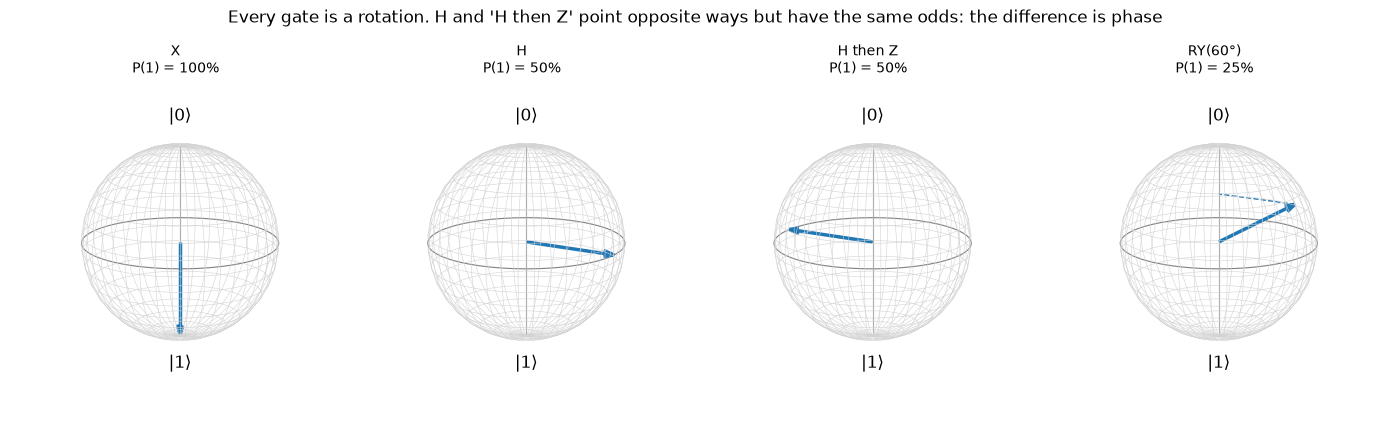


Sequences of gates, each starting from |0>
Sequence  final state                measured 0 / 1
H         +0.707|0>  +0.707|1>           508 / 492
X, X      +1.000|0>                     1000 / 0
H, H      +1.000|0>                     1000 / 0
H, Z, H   +1.000|1>                        0 / 1000


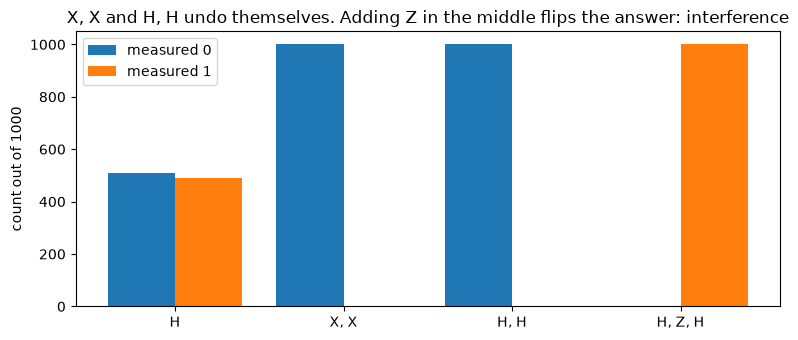


Controlled-RY(60°) circuit:
     ╭───╮             
q0 : ┤ h ├──────●──────
     ╰───╯╭─────┴─────╮
q1 : ─────┤ ry(1.047) ├
          ╰───────────╯

Outcome    theory  measured
  00        50.0%     50.6%
  01         0.0%      0.0%
  10        37.5%     35.8%
  11        12.5%     13.6%

When the control is 0, the target is never 1 (count of 01 = 0).
When the control is 1, the target is 1 in 28% of cases (theory 25%).


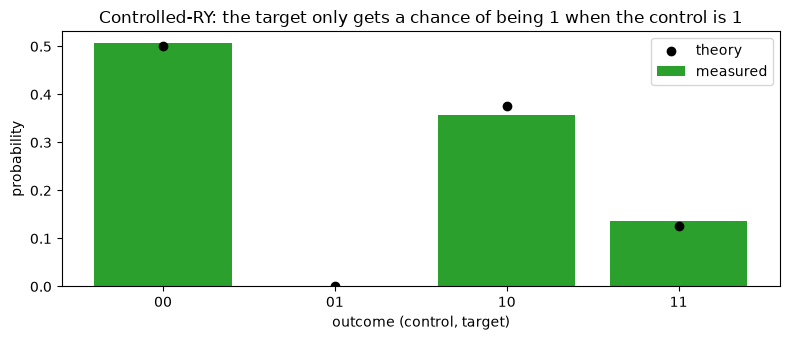


Bell circuit:
     ╭───╮     
q0 : ┤ h ├──●──
     ╰───╯╭─┴─╮
q1 : ─────┤ x ├
          ╰───╯

Step by step:
  Start          +1.000|00>
  After H on q0  +0.707|00>  +0.707|10>
  After CNOT     +0.707|00>  +0.707|11>
  Measured       {'00': 492, '11': 508}


In [23]:
#Introduction to quantum gates and quantum circuits
# Uses the Bloch sphere helpers and the bell() kernel from the Part 2 cell: run that cell first.


def show_state(state):
    """Write a state as amplitudes, e.g. 0.707|00> + 0.707|11> (skipping zeros)."""
    amps = np.array(state)
    n = int(np.log2(len(amps)))
    terms = []
    for i, amp in enumerate(amps):
        if abs(amp) > 1e-6:
            label = "".join(str((i >> k) & 1) for k in range(n))   # qubit 0 written first
            terms.append(f"{amp.real:+.3f}|{label}>")
    return "  ".join(terms)


# --- 3.2 Single-qubit gates on the Bloch sphere ------------------------------

@cudaq.kernel
def apply_x():
    q = cudaq.qubit()
    x(q)

@cudaq.kernel
def apply_h():
    q = cudaq.qubit()
    h(q)

@cudaq.kernel
def apply_h_then_z():
    q = cudaq.qubit()
    h(q)
    z(q)                   # flips the sign of beta

@cudaq.kernel
def apply_ry(theta: float):
    q = cudaq.qubit()
    ry(theta, q)


single_gates = [
    ("X",        apply_x,        ()),
    ("H",        apply_h,        ()),
    ("H then Z", apply_h_then_z, ()),
    ("RY(60°)",  apply_ry,       (np.radians(60),)),
]

print("Single-qubit gates, each starting from |0>")
print(f"{'Gate':<10}{'alpha':>8}{'beta':>8}{'P(0)':>7}{'P(1)':>7}{'measured 0 / 1':>17}")

fig = plt.figure(figsize=(14, 4))
for i, (name, kernel, args) in enumerate(single_gates):
    state = cudaq.get_state(kernel, *args)
    alpha, beta = np.array(state)
    counts = cudaq.sample(kernel, *args, shots_count=SHOTS)

    print(f"{name:<10}{alpha.real:>8.3f}{beta.real:>8.3f}{abs(alpha)**2:>7.0%}{abs(beta)**2:>7.0%}"
          f"{counts.count('0'):>10} / {counts.count('1')}")

    ax = fig.add_subplot(1, len(single_gates), i + 1, projection="3d")
    draw_bloch(ax, qubit_on_its_own(state, 0), f"{name}\nP(1) = {abs(beta)**2:.0%}")

fig.suptitle("Every gate is a rotation. H and 'H then Z' point opposite ways but have the same odds: "
             "the difference is phase", y=1.05)
plt.tight_layout()
plt.show()


# --- 3.3 / 3.4 Undoing gates and interference ---------------------------------

@cudaq.kernel
def x_x():
    q = cudaq.qubit()
    x(q)
    x(q)

@cudaq.kernel
def h_h():
    q = cudaq.qubit()
    h(q)
    h(q)

@cudaq.kernel
def h_z_h():
    q = cudaq.qubit()
    h(q)
    z(q)
    h(q)


sequences = [("H", apply_h), ("X, X", x_x), ("H, H", h_h), ("H, Z, H", h_z_h)]

print("\nSequences of gates, each starting from |0>")
print(f"{'Sequence':<10}{'final state':<26}{'measured 0 / 1':>15}")

zeros, ones = [], []
for name, kernel in sequences:
    counts = cudaq.sample(kernel, shots_count=SHOTS)
    zeros.append(counts.count("0"))
    ones.append(counts.count("1"))
    print(f"{name:<10}{show_state(cudaq.get_state(kernel)):<26}{zeros[-1]:>8} / {ones[-1]}")

labels = [name for name, _ in sequences]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(positions - 0.2, zeros, width=0.4, label="measured 0", color="tab:blue")
ax.bar(positions + 0.2, ones, width=0.4, label="measured 1", color="tab:orange")
ax.set_xticks(positions, labels)
ax.set_ylabel(f"count out of {SHOTS}")
ax.set_title("X, X and H, H undo themselves. Adding Z in the middle flips the answer: interference")
ax.legend()
plt.tight_layout()
plt.show()


# --- 3.5 The controlled-RY ----------------------------------------------------

@cudaq.kernel
def controlled_ry(theta: float):
    q = cudaq.qvector(2)
    h(q[0])                        # control: an equal blend of 0 and 1
    ry.ctrl(theta, q[0], q[1])     # rotate the target only when the control is 1


theta = np.radians(60)             # RY(60°) gives P(1) = sin²(30°) = 25%
counts = cudaq.sample(controlled_ry, theta, shots_count=SHOTS)

print("\nControlled-RY(60°) circuit:")
print(cudaq.draw(controlled_ry, theta))
print(f"{'Outcome':<9}{'theory':>8}{'measured':>10}")
theory = {"00": 0.5, "01": 0.0, "10": 0.5 * np.cos(theta / 2)**2, "11": 0.5 * np.sin(theta / 2)**2}
for outcome, p in theory.items():
    print(f"  {outcome:<7}{p:>8.1%}{counts.count(outcome) / SHOTS:>10.1%}")

control_was_1 = counts.count("10") + counts.count("11")
print(f"\nWhen the control is 0, the target is never 1 (count of 01 = {counts.count('01')}).")
print(f"When the control is 1, the target is 1 in {counts.count('11') / control_was_1:.0%} of cases "
      f"(theory {np.sin(theta / 2)**2:.0%}).")

fig, ax = plt.subplots(figsize=(8, 3.5))
outcomes = list(theory)
ax.bar(outcomes, [counts.count(o) / SHOTS for o in outcomes], color="tab:green", label="measured")
ax.scatter(outcomes, list(theory.values()), color="black", zorder=3, label="theory")
ax.set_xlabel("outcome (control, target)")
ax.set_ylabel("probability")
ax.set_title("Controlled-RY: the target only gets a chance of being 1 when the control is 1")
ax.legend()
plt.tight_layout()
plt.show()


# --- 3.6 Reading a circuit step by step -------------------------------------

@cudaq.kernel
def bell_up_to(steps: int):
    q = cudaq.qvector(2)
    if steps >= 1:
        h(q[0])
    if steps >= 2:
        x.ctrl(q[0], q[1])


print("\nBell circuit:")
print(cudaq.draw(bell))
print("Step by step:")
for steps, description in enumerate(["Start", "After H on q0", "After CNOT"]):
    print(f"  {description:<15}{show_state(cudaq.get_state(bell_up_to, steps))}")
print(f"  {'Measured':<15}{dict(cudaq.sample(bell, shots_count=SHOTS).items())}")


# Part 4: The Bernoulli Random Variable

## 4.1 What is a Bernoulli variable?

A **Bernoulli random variable** is the simplest random quantity there is: a yes/no outcome. It equals `1` with probability $p$ and `0` otherwise, like a coin that lands heads with probability $p$.

$$
X \in \{0, 1\}, \qquad P(X = 1) = p, \qquad P(X = 0) = 1 - p
$$

Its average (expected value) is simply $p$, and its variance measures how uncertain the outcome is:

$$
\mathbb{E}[X] = p, \qquad \text{Var}(X) = p\,(1 - p)
$$

The variance is largest at $p = 50\%$, when the outcome is hardest to predict, and zero at $p = 0$ or $p = 1$, when the outcome is certain.

## 4.2 A rebate example

Part 1 showed that reaching a new tier triggers a **true-up**: all earlier spend is re-rated at the higher rate. Whether a customer reaches Tier 3 by year end is a Bernoulli variable:

$$
X = \begin{cases} 1 & \text{customer reaches 25,000 units (true-up paid)} \\ 0 & \text{customer stays in Tier 2} \end{cases}
$$

Suppose the customer is forecast at about £1.5m of spend, so reaching Tier 3 triggers a true-up of $2\% \times £1.5\text{m} = £30{,}000$. Suppose also that the customer has a **30% chance** of getting there. The supplier's **expected true-up cost** is then

$$
\mathbb{E}[\text{cost}] = p \times £30{,}000 = 0.30 \times £30{,}000 = £9{,}000
$$

This is the basic building block of rebate liability: a *probability* of reaching a tier multiplied by the *cost* of paying it. The hard part in practice is knowing $p$.

## 4.3 Loading a probability into a qubit

A qubit is a natural home for a Bernoulli variable. From Part 3, the RY gate tilts the arrow so that $P(1) = \sin^2(\theta/2)$. To load a chosen probability $p$, pick the angle

$$
\theta = 2\arcsin\sqrt{p}
$$

The qubit is then in the state

$$
|\psi\rangle = \sqrt{1 - p}\;|0\rangle + \sqrt{p}\;|1\rangle
$$

**Measuring the qubit is one Bernoulli trial.** It gives `1` with probability $p$ and `0` otherwise. For $p = 30\%$, the angle is $\theta \approx 66.4°$ and the state is $0.837\,|0\rangle + 0.548\,|1\rangle$.

On the Bloch sphere, the higher $p$ is, the further the arrow tilts towards $|1\rangle$ at the south pole.

## 4.4 Estimating p by measuring

If $p$ is unknown, the obvious way to estimate it is to prepare and measure the qubit $N$ times and count the `1`s:

$$
\hat{p} = \frac{\text{number of 1s}}{N}
$$

This is exactly how classical **Monte Carlo simulation** works: run many random scenarios and count. The estimate improves with more shots, but slowly. Its typical error (the standard error) is

$$
\text{error} \approx \sqrt{\frac{p\,(1 - p)}{N}}
$$

For $p = 30\%$:

| Shots $N$ | Typical error in $\hat{p}$ | Typical error in the £9,000 cost |
|---|---|---|
| 100 | ± 4.6% | ± £1,370 |
| 1,000 | ± 1.4% | ± £430 |
| 10,000 | ± 0.46% | ± £140 |

The error shrinks like $1/\sqrt{N}$, so **10× more accuracy costs 100× more shots**. For a real portfolio with thousands of customers, many tiers and uncertain volumes, this becomes expensive quickly.

This limit is the target for **quantum amplitude estimation**, which uses the interference ideas from Part 3 to reach an error that shrinks like $1/N$. For the same accuracy, it needs roughly the *square root* of the number of shots.

## 4.5 Several customers

Each customer can be given their own qubit, loaded with their own probability. With three customers there are $2^3 = 8$ possible scenarios of who reaches Tier 3, and a single measurement of all three qubits samples one of them.

| Customer | P(reaches Tier 3) | True-up if reached | Expected cost |
|---|---|---|---|
| A | 30% | £30,000 | £9,000 |
| B | 60% | £12,000 | £7,200 |
| C | 10% | £50,000 | £5,000 |
| **Portfolio** | | | **£21,200** |

Here each customer is independent. The real value of qubits appears when outcomes are **linked**, for example when customers in the same market tend to grow together. Those links can be built in with the controlled gates from Part 3, which makes the scenarios much harder to enumerate classically.

## Summary

| Idea | In plain terms |
|---|---|
| Bernoulli variable | A yes/no outcome that is `1` with probability $p$ |
| Expected value | The average outcome, equal to $p$ |
| Rebate meaning | $p$ is the chance of reaching a tier; $p \times$ true-up is the expected cost |
| Loading into a qubit | RY with $\theta = 2\arcsin\sqrt{p}$ gives $\sqrt{1-p}\,\lvert 0\rangle + \sqrt{p}\,\lvert 1\rangle$ |
| Measuring | One Bernoulli trial per shot |
| Estimating by sampling | Error shrinks like $1/\sqrt{N}$, so 100× the shots for 10× the accuracy |
| Several customers | One qubit each; $n$ customers give $2^n$ scenarios |

Loading p = 30% into a qubit
  angle θ = 2·arcsin(√p) = 66.4°
  state   = 0.837|0> + 0.548|1>
  P(1)    = 30.0%
  Expected true-up cost = p × £30,000 = £9,000


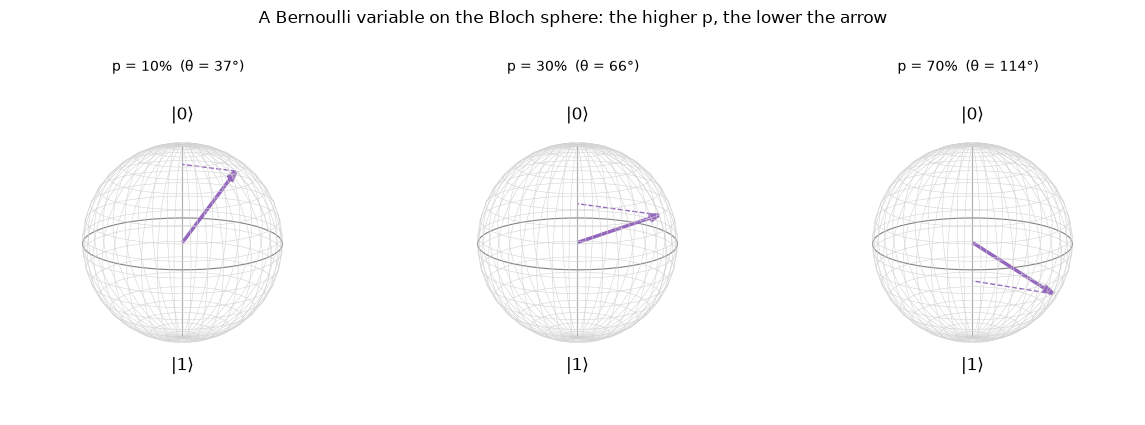


Estimating p = 30% by measuring (20 repeats per row)
   Shots  typical error   theory √(p(1-p)/N)      cost estimate range
     100          4.12%                4.58%         £7,200 – £12,600
   1,000          1.61%                1.45%         £8,040 – £10,110
  10,000          0.30%                0.46%          £8,847 – £9,147
10× more accuracy needs 100× more shots.


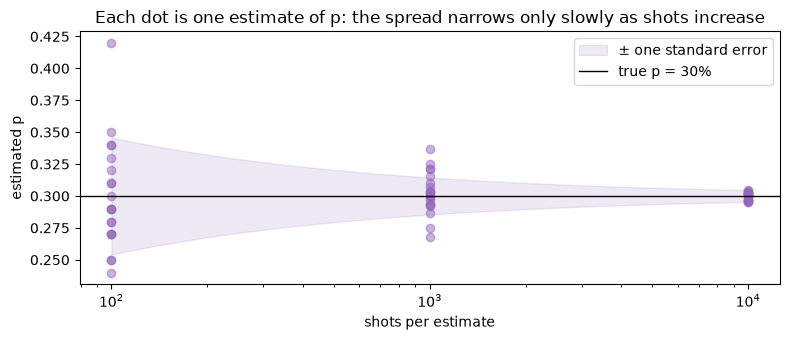


Three customers, 1000 measured scenarios (1 = reaches Tier 3)
A B C    count  true-up cost
0 1 0      402       £12,000
0 0 0      237            £0
1 1 0      166       £42,000
1 0 0       90       £30,000
0 1 1       43       £62,000
0 0 1       26       £50,000
1 0 1       22       £80,000
1 1 1       14       £92,000

Expected true-up cost: estimated £21,510, exact £21,200


In [24]:
#Introduction to Bernoulli vairable
# Uses the Bloch sphere helpers from the Part 2 cell: run that cell first.


def bernoulli_angle(p):
    """RY angle that loads probability p into a qubit: P(1) = sin²(θ/2) = p."""
    return 2 * np.arcsin(np.sqrt(p))


@cudaq.kernel
def bernoulli(theta: float):
    q = cudaq.qubit()
    ry(theta, q)          # the qubit is now 1 with probability p


# --- 4.3 Loading a probability into a qubit ----------------------------------

TRUE_UP = 30_000          # £ extra rebate if the customer reaches Tier 3 (2% × £1.5m)
p = 0.30                  # chance the customer reaches Tier 3

theta = bernoulli_angle(p)
alpha, beta = np.array(cudaq.get_state(bernoulli, theta))

print(f"Loading p = {p:.0%} into a qubit")
print(f"  angle θ = 2·arcsin(√p) = {np.degrees(theta):.1f}°")
print(f"  state   = {alpha.real:.3f}|0> + {beta.real:.3f}|1>")
print(f"  P(1)    = {abs(beta)**2:.1%}")
print(f"  Expected true-up cost = p × £{TRUE_UP:,} = £{p * TRUE_UP:,.0f}")

fig = plt.figure(figsize=(12, 4))
for i, prob in enumerate([0.10, 0.30, 0.70]):
    state = cudaq.get_state(bernoulli, bernoulli_angle(prob))
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    draw_bloch(ax, qubit_on_its_own(state, 0),
               f"p = {prob:.0%}  (θ = {np.degrees(bernoulli_angle(prob)):.0f}°)", "tab:purple")
fig.suptitle("A Bernoulli variable on the Bloch sphere: the higher p, the lower the arrow", y=1.05)
plt.tight_layout()
plt.show()


# --- 4.4 Estimating p by measuring --------------------------------------------

shot_counts = [100, 1_000, 10_000]
REPEATS = 20              # repeat each experiment to see how much the estimate varies

print(f"\nEstimating p = {p:.0%} by measuring ({REPEATS} repeats per row)")
print(f"{'Shots':>8}{'typical error':>15}{'theory √(p(1-p)/N)':>21}{'cost estimate range':>25}")

estimates = {}
for shots in shot_counts:
    runs = [cudaq.sample(bernoulli, theta, shots_count=shots).count("1") / shots
            for _ in range(REPEATS)]
    estimates[shots] = runs
    typical_error = np.std(runs)
    theory_error = np.sqrt(p * (1 - p) / shots)
    low, high = min(runs) * TRUE_UP, max(runs) * TRUE_UP
    print(f"{shots:>8,}{typical_error:>15.2%}{theory_error:>21.2%}"
          f"{f'£{low:,.0f} – £{high:,.0f}':>25}")

print("10× more accuracy needs 100× more shots.")

fig, ax = plt.subplots(figsize=(8, 3.5))
for shots, runs in estimates.items():
    ax.scatter([shots] * len(runs), runs, color="tab:purple", alpha=0.5)
n = np.logspace(2, 4, 100)
band = np.sqrt(p * (1 - p) / n)
ax.fill_between(n, p - band, p + band, color="tab:purple", alpha=0.15, label="± one standard error")
ax.axhline(p, color="black", linewidth=1, label=f"true p = {p:.0%}")
ax.set_xscale("log")
ax.set_xlabel("shots per estimate")
ax.set_ylabel("estimated p")
ax.set_title("Each dot is one estimate of p: the spread narrows only slowly as shots increase")
ax.legend()
plt.tight_layout()
plt.show()


# --- 4.5 Several customers ------------------------------------------------------

@cudaq.kernel
def portfolio(thetas: list[float]):
    q = cudaq.qvector(len(thetas))         # one qubit per customer
    for i in range(len(thetas)):
        ry(thetas[i], q[i])                # load each customer's probability


customers = ["A", "B", "C"]
probs = [0.30, 0.60, 0.10]                  # chance each customer reaches Tier 3
true_ups = [30_000, 12_000, 50_000]         # £ true-up each would trigger

counts = cudaq.sample(portfolio, [bernoulli_angle(pr) for pr in probs], shots_count=SHOTS)

print(f"\nThree customers, {SHOTS} measured scenarios (1 = reaches Tier 3)")
print(f"{'A B C':<8}{'count':>6}{'true-up cost':>14}")
estimated_cost = 0
for bits, count in sorted(counts.items(), key=lambda item: -item[1]):
    cost = sum(int(b) * c for b, c in zip(bits, true_ups))
    estimated_cost += cost * count / SHOTS
    print(f"{' '.join(bits):<8}{count:>6}{f'£{cost:,}':>14}")

exact_cost = sum(pr * c for pr, c in zip(probs, true_ups))
print(f"\nExpected true-up cost: estimated £{estimated_cost:,.0f}, exact £{exact_cost:,.0f}")


# Part 5: The Grover Operator

## 5.1 The idea: amplifying the outcome we care about

Part 4 loaded a probability into a qubit: measuring it gives the **"good"** outcome (`1`, the customer reaches Tier 3) with probability $p$. When $p$ is small, that outcome rarely appears, so learning anything about it takes many shots.

The **Grover operator** $Q$ is a fixed sequence of gates that makes the good outcome **more likely each time it is applied**. It does this by using interference (Part 3.4): the amplitude of the good outcome builds up, and the amplitude of the bad outcomes cancels away. This is called **amplitude amplification**.

## 5.2 Building the Grover operator

Call the circuit that loads the probabilities $A$. In Part 4, $A$ is a single RY gate. The prepared state splits into a good part and a bad part:

$$
A\,|0\rangle = \sqrt{1-p}\;|\text{bad}\rangle + \sqrt{p}\;|\text{good}\rangle
$$

The Grover operator is made of **two reflections**:

1. **Mark the good outcome.** Flip the sign of $|\text{good}\rangle$ and leave $|\text{bad}\rangle$ alone. This is exactly what the Z gate did in the H, Z, H example from Part 3.4. The odds don't change, only the hidden sign.
2. **Reflect about the starting state.** Undo the preparation ($A^\dagger$), flip the sign of $|0\rangle$, then redo the preparation ($A$).

$$
Q = \underbrace{A \, S_0 \, A^\dagger}_{\text{reflect about the start}} \; \underbrace{S_{\text{good}}}_{\text{mark good}}
$$

Neither reflection changes the probabilities on its own. **Together, they make a rotation**, and that is the whole trick.

## 5.3 The picture: a rotation

Every state of the form above sits on a quarter circle, with "bad" along one axis and "good" along the other. Write the starting point as an angle $\theta_p$ from the bad axis:

$$
A\,|0\rangle = \cos\theta_p\,|\text{bad}\rangle + \sin\theta_p\,|\text{good}\rangle, \qquad p = \sin^2\theta_p
$$

(This $\theta_p$ is half of the RY angle from Part 4.)

**Each Grover step rotates the state by $2\theta_p$ towards "good".** After $k$ steps, the angle is $(2k+1)\,\theta_p$, so

$$
P(\text{good after } k \text{ steps}) = \sin^2\!\big((2k+1)\,\theta_p\big)
$$

## 5.4 A worked example

For a customer with a $p = 10\%$ chance of reaching Tier 3, $\theta_p = \arcsin\sqrt{0.1} \approx 18.4°$, so each step rotates the state by about $36.9°$:

| Steps $k$ | Angle $(2k+1)\,\theta_p$ | P(good) |
|---|---|---|
| 0 | 18.4° | 10.0% |
| 1 | 55.3° | 67.6% |
| 2 | 92.2° | 99.9% |
| 3 | 129.0° | 60.3% |
| 4 | 165.9° | 5.9% |

**After two steps, a 10% outcome has become almost certain.** Past that point, the rotation **overshoots** the good axis and the probability falls again. P(good) rises and falls in a regular wave as $k$ increases.

## 5.5 Several customers

The same recipe works on any number of qubits. With two customers A (30%) and B (60%), define "good" as the scenario where **both** reach Tier 3, which has probability $0.3 \times 0.6 = 18\%$.

- **Marking** now uses a controlled-Z, which flips the sign of $|11\rangle$ only.
- **Reflecting about the start** undoes both RY gates, flips the sign of $|00\rangle$, and redoes them.

One Grover step lifts the "both reach Tier 3" scenario from 18% to about 94%.

For a single qubit, $Q$ works out to be just a larger RY rotation. **The value of Grover shows on bigger circuits:** when $A$ models a whole portfolio with linked customers, nobody can write down $p$ directly, yet $Q$ still rotates by exactly $2\theta_p$.

## 5.6 Two uses of the Grover operator

The rotation can be used in two ways:

| Use | What it does | Rebate question it answers |
|---|---|---|
| **Grover search** | Apply $Q$ until the good outcome is nearly certain, about $\tfrac{\pi}{4\sqrt{p}}$ steps, then measure | *Find* a scenario or design that meets a condition |
| **Amplitude estimation** | Measure *how fast* $Q$ rotates the state, then read off $\theta_p$ and so $p$ | *Estimate* the probability of reaching a tier, or the expected rebate cost |

The rise-and-fall wave from 5.4 is the key to the second use. **Its speed depends only on $p$**: a larger $p$ gives a faster wave. Amplitude estimation measures that speed very precisely, which is why it can estimate $p$ with error shrinking like $1/N$ rather than the $1/\sqrt{N}$ of simple sampling from Part 4.

## Summary

| Idea | In plain terms |
|---|---|
| Amplitude amplification | Make a rare "good" outcome more likely, using interference |
| Mark | Flip the sign of the good outcome (Z, or controlled-Z for scenarios) |
| Reflect about the start | Undo $A$, flip the sign of $\lvert 0\rangle$, redo $A$ |
| Grover operator $Q$ | Mark, then reflect: together a rotation by $2\theta_p$ |
| After $k$ steps | P(good) $= \sin^2((2k+1)\,\theta_p)$, rising, then overshooting |
| Grover search | Stop at the peak to find the good outcome |
| Amplitude estimation | Measure the speed of the wave to estimate $p$ |

One Grover step, drawn as a circuit:
     ╭────────────╮╭───╮╭─────────────╮╭───╮╭───╮╭───╮╭────────────╮
q0 : ┤ ry(0.6435) ├┤ z ├┤ ry(-0.6435) ├┤ x ├┤ z ├┤ x ├┤ ry(0.6435) ├
     ╰────────────╯╰───╯╰─────────────╯╰───╯╰───╯╰───╯╰────────────╯

p = 10%,  θp = 18.4°,  each step rotates by 2θp = 36.9°

 Steps k  angle (2k+1)θp  P(good) theory  P(good) measured
       0           18.4°           10.0%             10.3%
       1           55.3°           67.6%             69.1%
       2           92.2°           99.9%             99.7%
       3          129.0°           60.3%             58.0%
       4          165.9°            5.9%              7.0%
       5          202.8°           15.0%             16.7%
P(good) rises to almost 100% after 2 steps, then overshoots and falls again.


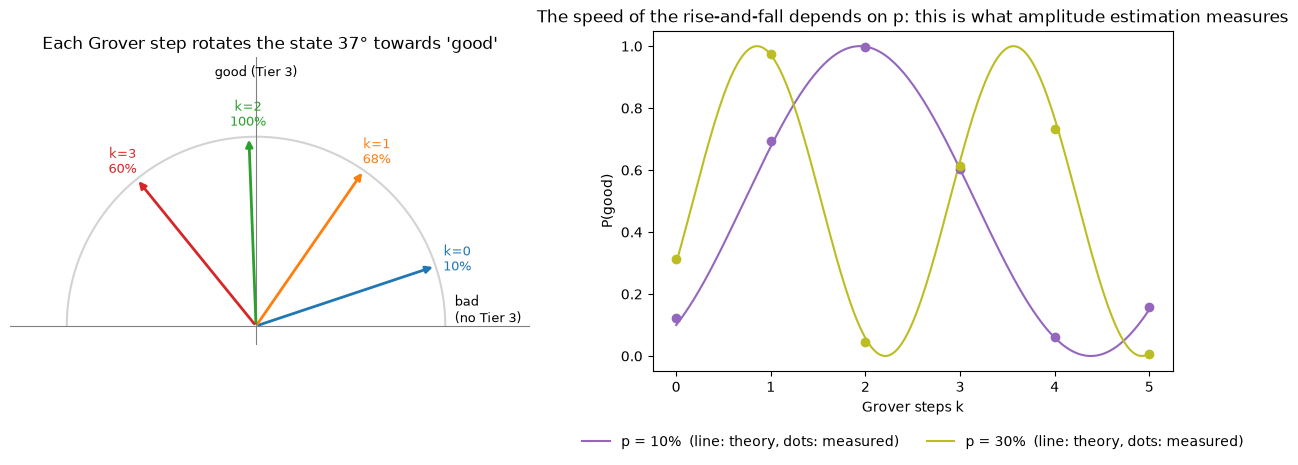


Two customers: P(A reaches Tier 3) = 30%, P(B reaches Tier 3) = 60%
'Good' scenario = both reach Tier 3, with p = 18%

k = 0:  00:  288  01:  408  10:  122  11:  182   theory P(11) = 18.0%
k = 1:  00:   17  01:   25  10:    7  11:  951   theory P(11) = 93.6%


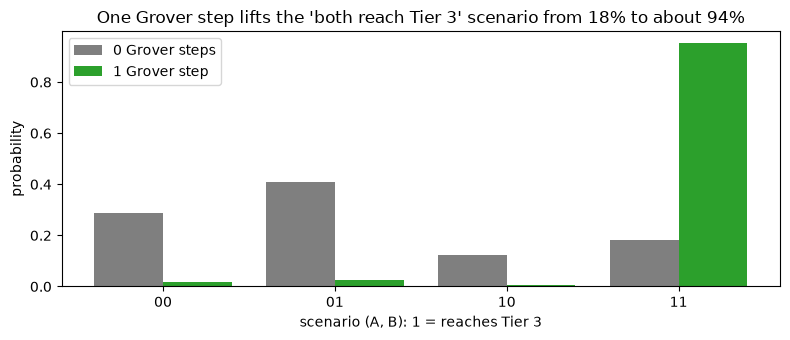

In [25]:
#Introduction to Grover operator
# Uses bernoulli_angle() from the Part 4 cell: run the Part 2 and Part 4 cells first.


# --- 5.2 / 5.6 The Grover operator for one customer --------------------------

@cudaq.kernel
def grover_one(theta: float, k: int):
    q = cudaq.qubit()
    ry(theta, q)              # A: load p (the "good" outcome is 1)
    for i in range(k):        # apply the Grover operator Q, k times
        z(q)                  #   1. mark the good outcome by flipping its sign
        ry(-theta, q)         #   2. undo A ...
        x(q)
        z(q)                  #      ... reflect about the starting point |0> ...
        x(q)
        ry(theta, q)          #      ... and redo A


p = 0.10                                   # chance the customer reaches Tier 3
theta = bernoulli_angle(p)                 # RY angle from Part 4
theta_p = np.arcsin(np.sqrt(p))            # angle in the good/bad plane: p = sin²(θp)

print("One Grover step, drawn as a circuit:")
print(cudaq.draw(grover_one, theta, 1))

print(f"p = {p:.0%},  θp = {np.degrees(theta_p):.1f}°,  each step rotates by 2θp = {np.degrees(2 * theta_p):.1f}°\n")
print(f"{'Steps k':>8}{'angle (2k+1)θp':>16}{'P(good) theory':>16}{'P(good) measured':>18}")

steps = range(6)
measured = []
for k in steps:
    counts = cudaq.sample(grover_one, theta, k, shots_count=SHOTS)
    measured.append(counts.count("1") / SHOTS)
    angle = (2 * k + 1) * theta_p
    print(f"{k:>8}{np.degrees(angle):>15.1f}°{np.sin(angle)**2:>16.1%}{measured[-1]:>18.1%}")

print("P(good) rises to almost 100% after 2 steps, then overshoots and falls again.")


# --- 5.3 The picture: a rotation in the good/bad plane -----------------------

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

t = np.linspace(0, np.pi, 200)
ax1.plot(np.cos(t), np.sin(t), color="lightgrey")
ax1.axhline(0, color="grey", linewidth=0.8)
ax1.axvline(0, color="grey", linewidth=0.8)
ax1.text(1.05, 0.02, "bad\n(no Tier 3)", fontsize=9)
ax1.text(0, 1.32, "good (Tier 3)", ha="center", fontsize=9)

for k, colour in zip(range(4), ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    angle = (2 * k + 1) * theta_p
    ax1.annotate("", xy=(np.cos(angle), np.sin(angle)), xytext=(0, 0),
                 arrowprops=dict(arrowstyle="-|>", color=colour, linewidth=2))
    ax1.text(1.12 * np.cos(angle), 1.12 * np.sin(angle), f"k={k}\n{np.sin(angle)**2:.0%}",
             color=colour, ha="center", va="center", fontsize=9)

ax1.set_xlim(-1.3, 1.45); ax1.set_ylim(-0.1, 1.42)
ax1.set_aspect("equal"); ax1.axis("off")
ax1.set_title(f"Each Grover step rotates the state {np.degrees(2 * theta_p):.0f}° towards 'good'")

# How P(good) rises and falls with k, for two different starting probabilities
k_smooth = np.linspace(0, 5, 200)
for prob, colour in [(0.10, "tab:purple"), (0.30, "tab:olive")]:
    tp = np.arcsin(np.sqrt(prob))
    ax2.plot(k_smooth, np.sin((2 * k_smooth + 1) * tp)**2, color=colour, label=f"p = {prob:.0%}  (line: theory, dots: measured)")
    points = [cudaq.sample(grover_one, bernoulli_angle(prob), k, shots_count=SHOTS).count("1") / SHOTS
              for k in steps]
    ax2.scatter(list(steps), points, color=colour, zorder=3)

ax2.set_xlabel("Grover steps k")
ax2.set_ylabel("P(good)")
ax2.set_title("The speed of the rise-and-fall depends on p: this is what amplitude estimation measures")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.tight_layout()
plt.show()


# --- 5.5 Two customers: amplify "both reach Tier 3" ---------------------------

@cudaq.kernel
def grover_two(theta_a: float, theta_b: float, k: int):
    q = cudaq.qvector(2)
    ry(theta_a, q[0])          # A: load each customer's probability
    ry(theta_b, q[1])
    for i in range(k):
        z.ctrl(q[0], q[1])     #   1. mark the good scenario |11> (both reach Tier 3)
        ry(-theta_b, q[1])     #   2. undo A ...
        ry(-theta_a, q[0])
        x(q[0])
        x(q[1])
        z.ctrl(q[0], q[1])     #      ... reflect about the starting point |00> ...
        x(q[0])
        x(q[1])
        ry(theta_a, q[0])      #      ... and redo A
        ry(theta_b, q[1])


p_a, p_b = 0.30, 0.60
p_both = p_a * p_b
angles = (bernoulli_angle(p_a), bernoulli_angle(p_b))
tp_both = np.arcsin(np.sqrt(p_both))

print(f"\nTwo customers: P(A reaches Tier 3) = {p_a:.0%}, P(B reaches Tier 3) = {p_b:.0%}")
print(f"'Good' scenario = both reach Tier 3, with p = {p_both:.0%}\n")

outcomes = ["00", "01", "10", "11"]
fig, ax = plt.subplots(figsize=(8, 3.5))
for k, offset, colour in [(0, -0.2, "tab:grey"), (1, 0.2, "tab:green")]:
    counts = cudaq.sample(grover_two, *angles, k, shots_count=SHOTS)
    print(f"k = {k}:  " + "  ".join(f"{o}: {counts.count(o):>4}" for o in outcomes)
          + f"   theory P(11) = {np.sin((2 * k + 1) * tp_both)**2:.1%}")
    ax.bar(np.arange(4) + offset, [counts.count(o) / SHOTS for o in outcomes], width=0.4,
           color=colour, label=f"{k} Grover step{'s' if k != 1 else ''}")

ax.set_xticks(range(4), outcomes)
ax.set_xlabel("scenario (A, B): 1 = reaches Tier 3")
ax.set_ylabel("probability")
ax.set_title("One Grover step lifts the 'both reach Tier 3' scenario from 18% to about 94%")
ax.legend()
plt.tight_layout()
plt.show()


In [26]:
#Introduction to quantum amplitude estimation   